# AuroraCast: exploratory data analysis (MS2)

Answers the proposal feedback: persistence **both ways** and the storm base rate (A1), the OMNI vs RTSW and nowcast vs definitive gaps (A3), and the number of independent storm events (B2). Targets and thresholds are frozen in the [README](../README.md).

**Test-set rule:** everything here uses 1998-2023 only (train 1998-2019, validation 2020-2023). The one exception is section 7, which counts storm events in 2024-2025 and scores nothing there.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from auroracast.baseline import LAST_COMPLETED, LAST_PUBLISHED, STORM_KP, count_storm_events, score_persistence
from auroracast.db import connect

conn = connect()
conn.autocommit = True
conn.execute("SET TIME ZONE 'UTC'")


def query(sql):
    cur = conn.execute(sql)
    return pd.DataFrame(cur.fetchall(), columns=[col.name for col in cur.description])


SPLITS = {"train 1998-2019": range(1998, 2020), "val 2020-2023": range(2020, 2024), "train+val": range(1998, 2024)}

omni_rows = query("SELECT count(*) AS n FROM omni_1min WHERE time_tag < '2024-01-01'").n[0]
assert omni_rows > 10_000_000, f"only {omni_rows} OMNI rows: connected to the wrong database?"
print(f"OMNI rows before 2024: {omni_rows:,}")

OMNI rows before 2024: 12,848,581


## 1. Kp and the storm base rate

A storm is Kp >= 5.0, so `5-` (4.67) does not count.

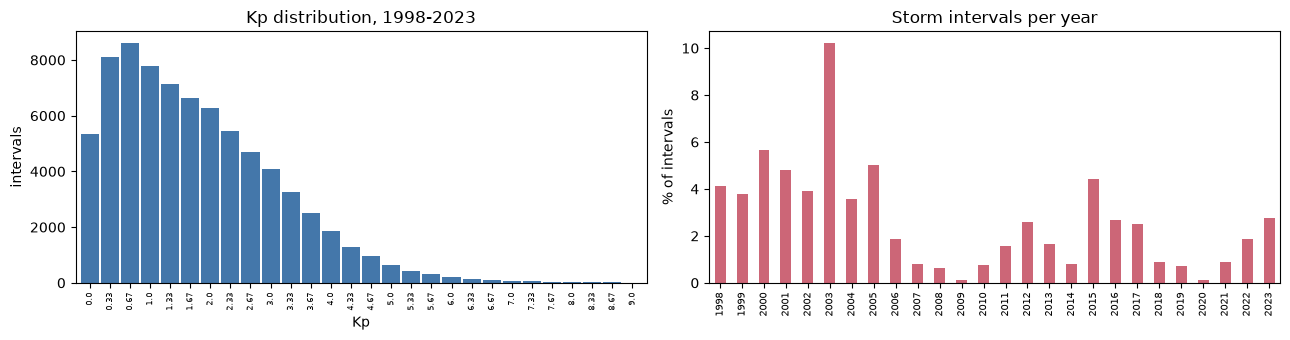

In [2]:
frame = query("SELECT interval_start, kp FROM kp WHERE interval_start < '2024-01-01' ORDER BY 1")
kp = frame.set_index(pd.to_datetime(frame.interval_start, utc=True)).kp.astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
kp.round(2).value_counts().sort_index().plot.bar(ax=axes[0], color="#4477aa", width=0.9)
axes[0].set(title="Kp distribution, 1998-2023", xlabel="Kp", ylabel="intervals")
axes[0].tick_params(axis="x", labelsize=6)
(kp >= STORM_KP).groupby(kp.index.year).mean().mul(100).plot.bar(ax=axes[1], color="#cc6677")
axes[1].set(title="Storm intervals per year", xlabel="", ylabel="% of intervals")
axes[1].tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()

## 2. Persistence both ways

- **Last completed:** Kp of `[t-3h, t)`.
- **Last published:** Kp of `[t-6h, t-3h)`, assumed to be complete and published before `t`. Section 3 tests that assumption.

History only holds definitive Kp, so neither variant reproduces the preliminary value really available at `t`. Section 3 measures how close that is.

intervals    mae  storm_intervals  storm_rate  \
split           variant                                                         
train 1998-2019 last completed      64279  0.626             1844       0.029   
                last published      64278  0.804             1844       0.029   
val 2020-2023   last completed      11688  0.631              164       0.014   
                last published      11688  0.812              164       0.014   
train+val       last completed      75967  0.627             2008       0.026   
                last published      75966  0.806             2008       0.026   

                                recall  precision  
split           variant                            
train 1998-2019 last completed   0.532      0.532  
                last published   0.395      0.395  
val 2020-2023   last completed   0.415      0.415  
                last published   0.250      0.250  
train+val       last completed   0.522      0.522  
                last published   0.383      0.383

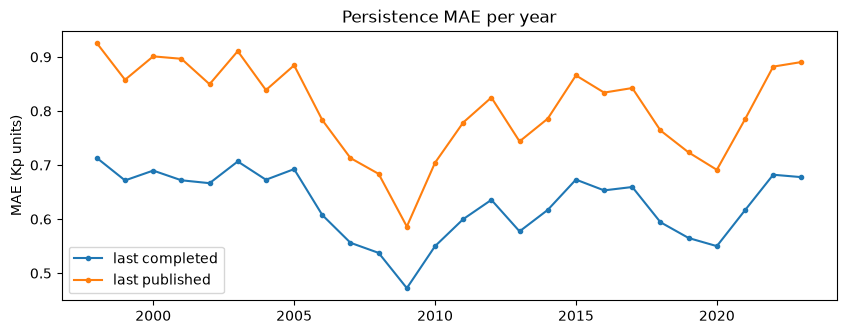

In [3]:
VARIANTS = {"last completed": LAST_COMPLETED, "last published": LAST_PUBLISHED}
scores = pd.DataFrame([
    {"split": split, "variant": name, **score_persistence(kp, lag, years)}
    for split, years in SPLITS.items() for name, lag in VARIANTS.items()
]).set_index(["split", "variant"])
display(scores.round(3))

fig, ax = plt.subplots(figsize=(10, 3.5))
for name, lag in VARIANTS.items():
    yearly = {year: score_persistence(kp, lag, [year])["mae"] for year in range(1998, 2024)}
    ax.plot(list(yearly), list(yearly.values()), marker="o", ms=3, label=name)
ax.set(title="Persistence MAE per year", ylabel="MAE (Kp units)")
ax.legend()
plt.show()

## 3. GFZ publication timing and nowcast vs definitive

From `kp_revisions`, recorded since polling began on 2026-10-31. Only intervals starting after polling began show real timing. Runs are irregular, so delays are upper limits.

In [4]:
timing = query('''
    SELECT interval_start, min(seen_at) AS first_seen, count(*) AS revisions
    FROM kp_revisions
    WHERE interval_start > (SELECT min(seen_at) FROM kp_revisions)
    GROUP BY 1 ORDER BY 1
''')
if timing.empty:
    print("No intervals observed from their start yet.")
else:
    hours = (pd.to_datetime(timing.first_seen, utc=True) - pd.to_datetime(timing.interval_start, utc=True)).dt.total_seconds() / 3600
    print(f"{len(timing)} intervals observed; first seen after interval start: median {hours.median():.1f} h, "
          f"share before the interval ended (< 3 h): {(hours < 3).mean():.0%}; mean revisions {timing.revisions.mean():.1f}")

revisions = query('''
    SELECT interval_start,
           (array_agg(kp ORDER BY seen_at DESC) FILTER (WHERE status = 'pre'))[1] AS last_pre,
           (array_agg(kp ORDER BY seen_at DESC) FILTER (WHERE status = 'def'))[1] AS definitive
    FROM kp_revisions GROUP BY 1
''').dropna()
if revisions.empty:
    print("No interval has both a preliminary and a definitive value yet: gap not measurable.")
else:
    gap = (revisions.last_pre.astype(float) - revisions.definitive.astype(float)).abs()
    print(f"Nowcast vs definitive over {len(revisions)} intervals: MAE {gap.mean():.3f}, max {gap.max():.2f}")

39 intervals observed; first seen after interval start: median 4.7 h, share before the interval ended (< 3 h): 23%; mean revisions 1.4
No interval has both a preliminary and a definitive value yet: gap not measurable.


## 4. OMNI data quality

Share of minutes per year with speed and Bz present, and which spacecraft supplied the magnetic field.

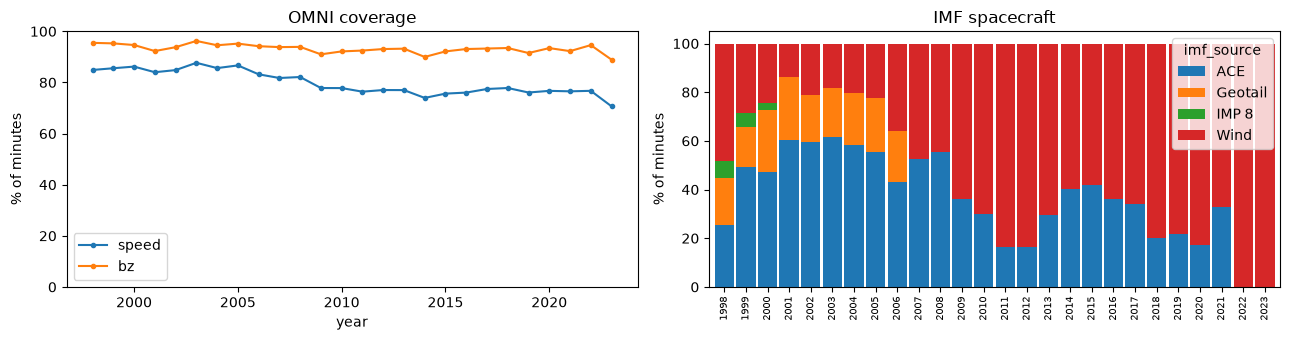

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
speed,84.9,85.6,86.2,84.0,84.8,87.7,85.6,86.7,83.2,81.7,...,74.0,75.6,76.0,77.4,77.8,76.1,76.7,76.5,76.7,70.7
bz,95.5,95.3,94.6,92.3,93.8,96.2,94.6,95.2,94.2,93.8,...,90.0,92.1,93.1,93.3,93.5,91.5,93.4,92.3,94.6,88.9
both_present,84.6,85.3,85.9,83.6,84.4,87.4,85.2,86.3,82.8,81.2,...,73.3,75.0,75.4,76.8,77.2,75.4,76.0,75.9,76.0,70.0


In [5]:
coverage = query('''
    SELECT EXTRACT(YEAR FROM time_tag)::int AS year,
           count(flow_speed) AS speed, count(bz_gsm) AS bz, count(*) FILTER (WHERE flow_speed IS NOT NULL AND bz_gsm IS NOT NULL) AS both_present
    FROM omni_1min WHERE time_tag < '2024-01-01' GROUP BY 1 ORDER BY 1
''').set_index("year")
minutes = pd.Series({y: 527040 if pd.Timestamp(y, 1, 1).is_leap_year else 525600 for y in coverage.index})
coverage_pct = coverage.div(minutes, axis=0).mul(100).astype(float)

sources = query('''
    SELECT EXTRACT(YEAR FROM time_tag)::int AS year, imf_source, count(*) AS n
    FROM omni_1min WHERE time_tag < '2024-01-01' AND imf_source IS NOT NULL GROUP BY 1, 2
''')
names = {50: "IMP 8", 51: "Wind", 60: "Geotail", 71: "ACE"}
source_mix = sources.assign(imf_source=sources.imf_source.map(names)).pivot(index="year", columns="imf_source", values="n").fillna(0).astype(float)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
coverage_pct[["speed", "bz"]].plot(ax=axes[0], marker="o", ms=3)
axes[0].set(title="OMNI coverage", ylabel="% of minutes", ylim=(0, 100))
source_mix.div(source_mix.sum(axis=1), axis=0).mul(100).plot.bar(stacked=True, ax=axes[1], width=0.9)
axes[1].set(title="IMF spacecraft", ylabel="% of minutes", xlabel="")
axes[1].tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.show()
display(coverage_pct.round(1).T)

## 5. Do the core features carry signal?

Training years only. Each window is the hour before `t` and ends before `t` (leakage rule 2). `kp_change` asks the useful question: does solar wind explain the *change* from the last completed Kp, which persistence cannot?

59,698 of 62,486 windows have at least 30 min of speed and Bz (95.5%)


,kp,kp_change
speed,0.552,-0.074
density,0.051,0.071
bz,-0.353,-0.107
ey,0.352,0.106


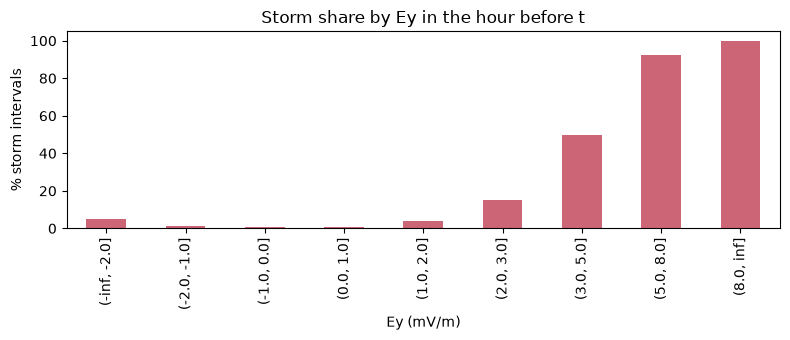

In [6]:
windows = query('''
    SELECT time_bucket('1 hour', time_tag) + INTERVAL '1 hour' AS t,
           avg(flow_speed) AS speed, avg(density) AS density, avg(bz_gsm) AS bz, avg(ey) AS ey,
           count(flow_speed) AS speed_minutes, count(bz_gsm) AS bz_minutes
    FROM omni_1min
    WHERE time_tag < '2020-01-01' AND EXTRACT(HOUR FROM time_tag)::int % 3 = 2
    GROUP BY 1
''')
windows = windows.set_index(pd.to_datetime(windows.t, utc=True)).drop(columns="t").astype(float).sort_index()
windows["kp"] = kp
windows["kp_change"] = kp - kp.shift(freq=LAST_COMPLETED * pd.Timedelta(hours=3))

usable = windows[(windows.speed_minutes >= 30) & (windows.bz_minutes >= 30)].dropna()
print(f"{len(usable):,} of {len(windows):,} windows have at least 30 min of speed and Bz ({len(usable) / len(windows):.1%})")
correlation = usable[["speed", "density", "bz", "ey", "kp", "kp_change"]].corr(method="spearman")[["kp", "kp_change"]].drop(["kp", "kp_change"])
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = pd.cut(usable.ey, [-np.inf, -2, -1, 0, 1, 2, 3, 5, 8, np.inf])
storm_share = usable.groupby(bins, observed=True).kp.agg(lambda s: (s >= STORM_KP).mean() * 100)
storm_share.plot.bar(ax=ax, color="#cc6677")
ax.set(title="Storm share by Ey in the hour before t", xlabel="Ey (mV/m)", ylabel="% storm intervals")
plt.tight_layout()
plt.show()

## 6. OMNI vs live RTSW

Hourly means for the minutes both sources cover. OMNI is shifted to the bow shock and RTSW is not, so short-lag differences are expected. A short overlap gives only a first indication.

In [7]:
overlap = query('''
    WITH omni AS (
        SELECT time_bucket('1 hour', time_tag) AS hour, avg(flow_speed) AS omni_speed, avg(density) AS omni_density, avg(bz_gsm) AS omni_bz
        FROM omni_1min WHERE time_tag >= (SELECT min(time_tag) FROM raw_rtsw_wind) GROUP BY 1
    ), wind AS (
        SELECT time_bucket('1 hour', time_tag) AS hour, avg(proton_speed) AS rtsw_speed, avg(proton_density) AS rtsw_density
        FROM raw_rtsw_wind WHERE active GROUP BY 1
    ), mag AS (
        SELECT time_bucket('1 hour', time_tag) AS hour, avg(bz_gsm) AS rtsw_bz FROM raw_rtsw_mag WHERE active GROUP BY 1
    )
    SELECT * FROM omni JOIN wind USING (hour) JOIN mag USING (hour) ORDER BY hour
''')
print(f"Overlapping hours: {len(overlap)}")
if len(overlap) >= 6:
    numeric = overlap.drop(columns="hour").astype(float)
    print(pd.DataFrame({
        var: {"mean absolute difference": (numeric[f"omni_{var}"] - numeric[f"rtsw_{var}"]).abs().mean(),
              "correlation": numeric[f"omni_{var}"].corr(numeric[f"rtsw_{var}"])}
        for var in ("speed", "density", "bz")
    }).round(3))
else:
    print("Too little overlap to report a gap yet; repeat once NASA extends the 2026 file.")

Overlapping hours: 33
                           speed  density     bz
mean absolute difference  16.648    1.174  1.209
correlation                0.927    0.793  0.637


## 7. Independent storm events

The only use of 2024-2025: storm *counts* from Kp alone, no model or baseline scores. Storm intervals under 24 hours apart count as one event.

In [8]:
storms = query("SELECT interval_start, kp FROM kp WHERE kp >= 5 AND interval_start < '2026-01-01' ORDER BY 1")
storm_kp = storms.set_index(pd.to_datetime(storms.interval_start, utc=True)).kp.astype(float)
periods = {**{k: v for k, v in SPLITS.items() if k != "train+val"}, "test 2024-2025": range(2024, 2026)}
display(pd.DataFrame([
    {"period": name, "storm_intervals": int(storm_kp.index.year.isin(list(years)).sum()),
     "independent_events": count_storm_events(storm_kp[storm_kp.index.year.isin(list(years))])}
    for name, years in periods.items()
]).set_index("period"))

,storm_intervals,independent_events
period,,
train 1998-2019,1844,533
val 2020-2023,164,77
test 2024-2025,253,61


## Findings (first run, 2026-11-05)

**Persistence.** Last completed is clearly stronger than last published (MAE 0.627 vs 0.806, 1998-2023). Targets are pinned to it in the [README](../README.md). Skill varies with solar activity: validation storm recall is only 0.415, because storms are rarer there.

**Publication delay.** Of 39 intervals observed from their start, 23 % were first seen before the interval ended, and the median first sighting was 4.7 h after the start. GitHub Actions runs are irregular, so these are upper limits and may overstate the delay. They still show that a value for `[t-3h, t)` is often not visible to our poller at `t`, which supports the feedback that published Kp can be more than one interval old. Revisions are rare (mean 1.4 per interval).

**Consequence for the model.** Under leakage rule 3, lagged Kp features may have to use older values than the baseline uses. The frozen baseline ignores the delay, so it is a deliberately hard bar.

**Nowcast vs definitive.** Not measurable yet: no interval has both values recorded. Repeat once definitive values arrive.

**OMNI quality.** Bz is present more often than speed, for example 95.5 % vs 84.9 % of minutes in 1998 and 88.9 % vs 70.7 % in 2023. In the training years, 95.5 % of the 62,486 hourly windows before `t` have at least 30 minutes of both, so data-gap handling matters but the windows are mostly usable.

**Signal.** In the training years, speed (Spearman 0.55), Bz (-0.35) and Ey (0.35) relate clearly to Kp, but only weakly to the *change* from the last completed Kp (|rho| about 0.07-0.11). Rank correlation misses non-linear effects and feature combinations, but this suggests that beating persistence by 10 % may be hard.

**OMNI vs RTSW (A3).** First indication from only 33 overlapping hours, using hourly means with RTSW unshifted and a different spacecraft (OMNI Wind, RTSW SOLAR1): mean absolute difference 16.6 km/s in speed (r 0.93), 1.17 /cc in density (r 0.79), 1.21 nT in Bz (r 0.64). This is too short for a conclusion. Repeat once NASA extends the 2026 file.

**Storm events (B2).** 533 independent events in training, 77 in validation and 61 in the test years (253 storm intervals, about 4.3 % of test intervals, roughly three times the validation rate). The decision threshold is set on a much calmer period than it will be tested on. Final results will state per-event hit rate out of the 61 events.

In [9]:
conn.close()